# Week 6 – Decision Trees and Random Forests
## Diabetes Health Indicators and Hospital Readmission

This week I apply **Decision Trees** and **Random Forests** to both healthcare datasets.

**Dataset 1 – BRFSS Diabetes Health Indicators:** predict Diabetes_binary using selected health indicators.

**Dataset 2 – Hospital Readmission:** predict whether a patient is readmitted within 30 days using selected hospital utilization variables.

Because both targets are imbalanced, I compare models using **accuracy, precision, recall, F1 score, ROC-AUC, confusion matrices, and feature importance**. I also compare Decision Tree depths to examine model complexity and overfitting.

In [21]:
# ============================================================
# 1. Import Libraries
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score, ConfusionMatrixDisplay

print("Libraries imported successfully.")


Libraries imported successfully.


# Part 1 – BRFSS Diabetes Health Indicators

The target is Diabetes_binary, where 0 represents no diabetes and 1 represents diabetes/prediabetes. The purpose is to compare a single Decision Tree with a Random Forest and identify the health indicators most useful for prediction.


In [22]:
# ============================================================
# 2. Load Health Dataset
# ============================================================

health_url = "https://raw.githubusercontent.com/jeganart/healthdatasetmilestone3/refs/heads/main/diabetes_binary_health_indicators_BRFSS2015.csv"
health_df = pd.read_csv(health_url)

print("Dataset shape:", health_df.shape)
display(health_df.head())


Dataset shape: (253680, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [23]:
# ============================================================
# 3. Health Target Distribution
# ============================================================

print("Missing values:", health_df.isnull().sum().sum())
print("\nTarget counts:")
print(health_df["Diabetes_binary"].value_counts())

print("\nTarget percentages:")
print(health_df["Diabetes_binary"].value_counts(normalize=True).mul(100).round(2))

Missing values: 0

Target counts:
Diabetes_binary
0.0    218334
1.0     35346
Name: count, dtype: int64

Target percentages:
Diabetes_binary
0.0    86.07
1.0    13.93
Name: proportion, dtype: float64


In [24]:
# ============================================================
# 4. Health Features and Train-Test Split
# ============================================================

health_features = [
    "HighBP", "HighChol", "BMI", "Smoker",
    "HeartDiseaseorAttack", "PhysActivity", "GenHlth", "Age"
]

X_health = health_df[health_features]
y_health = health_df["Diabetes_binary"].astype(int)

Xh_train, Xh_test, yh_train, yh_test = train_test_split(
    X_health, y_health, test_size=0.20, random_state=42, stratify=y_health
)

print("Features:", health_features)
print("Training observations:", len(Xh_train))
print("Testing observations:", len(Xh_test))


Features: ['HighBP', 'HighChol', 'BMI', 'Smoker', 'HeartDiseaseorAttack', 'PhysActivity', 'GenHlth', 'Age']
Training observations: 202944
Testing observations: 50736


## Health Decision Tree

The Decision Tree uses entropy and information gain to choose splits. I limit max_depth and require a minimum number of observations in each leaf to control model complexity. class_weight="balanced" gives more weight to the smaller diabetes class.

In [25]:
# ============================================================
# 5. Health Decision Tree
# ============================================================

health_tree = DecisionTreeClassifier(
    criterion="entropy", max_depth=5, min_samples_leaf=50,
    class_weight="balanced", random_state=42
)

health_tree.fit(Xh_train, yh_train)

health_tree_pred = health_tree.predict(Xh_test)
health_tree_prob = health_tree.predict_proba(Xh_test)[:, 1]

health_tree_accuracy = accuracy_score(yh_test, health_tree_pred)
health_tree_precision = precision_score(yh_test, health_tree_pred)
health_tree_recall = recall_score(yh_test, health_tree_pred)
health_tree_f1 = f1_score(yh_test, health_tree_pred)
health_tree_auc = roc_auc_score(yh_test, health_tree_prob)

print("HEALTH DECISION TREE")
print("Accuracy:", round(health_tree_accuracy, 4))
print("Precision:", round(health_tree_precision, 4))
print("Recall:", round(health_tree_recall, 4))
print("F1 Score:", round(health_tree_f1, 4))
print("ROC-AUC:", round(health_tree_auc, 4))

HEALTH DECISION TREE
Accuracy: 0.6916
Precision: 0.2803
Recall: 0.7744
F1 Score: 0.4117
ROC-AUC: 0.8001


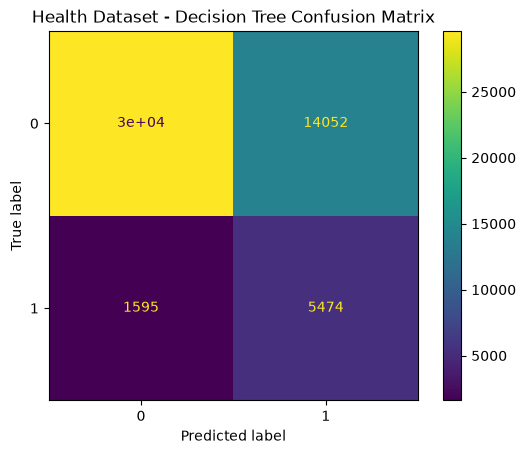

In [26]:
# Health Decision Tree Confusion Matrix

ConfusionMatrixDisplay.from_predictions(yh_test, health_tree_pred)
plt.title("Health Dataset - Decision Tree Confusion Matrix")
plt.show()

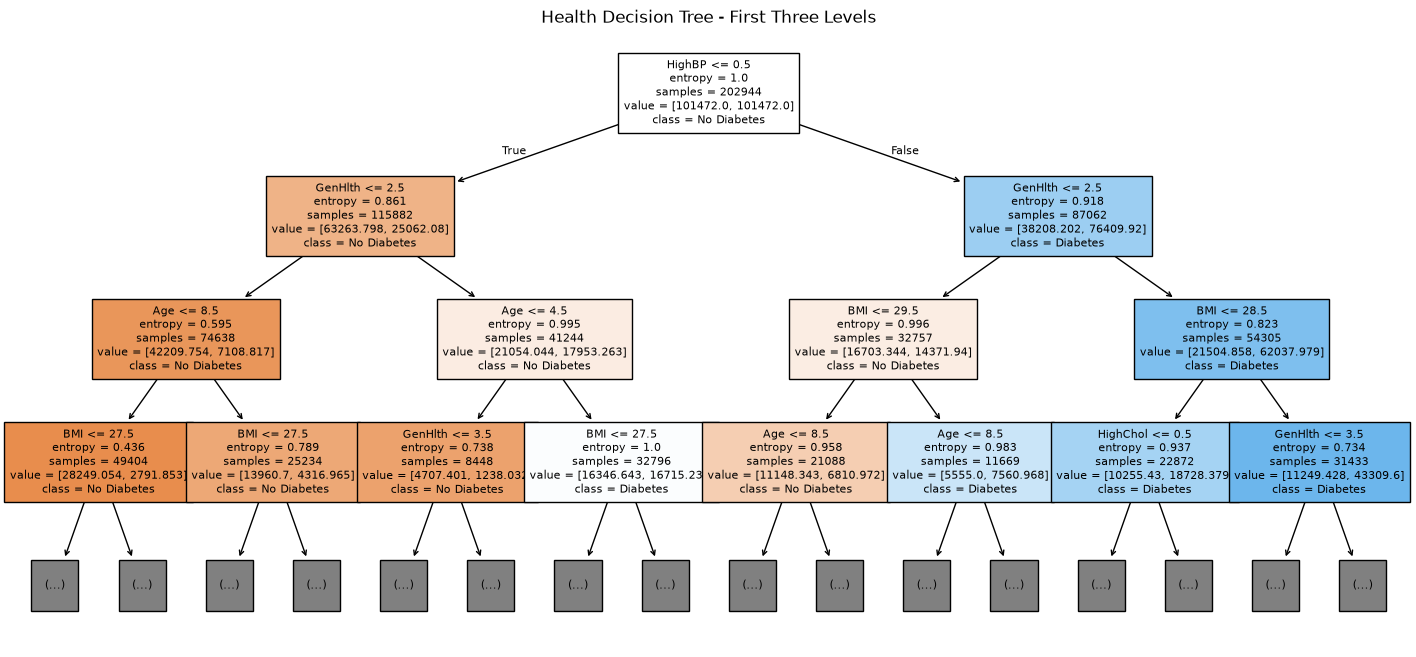

In [27]:
# First Three Levels of the Health Decision Tree

plt.figure(figsize=(18, 8))
plot_tree(
    health_tree, feature_names=health_features,
    class_names=["No Diabetes", "Diabetes"],
    filled=True, max_depth=3, fontsize=8
)
plt.title("Health Decision Tree - First Three Levels")
plt.show()


## Health Random Forest

Random Forest combines predictions from many Decision Trees. Random sampling and random feature selection make the trees different from one another, which can improve stability and reduce the dependence on any single tree.


In [28]:
# ============================================================
# 6. Health Random Forest
# ============================================================

health_rf = RandomForestClassifier(
    n_estimators=100, max_depth=10, min_samples_leaf=20,
    class_weight="balanced", random_state=42, n_jobs=-1
)

health_rf.fit(Xh_train, yh_train)

health_rf_pred = health_rf.predict(Xh_test)
health_rf_prob = health_rf.predict_proba(Xh_test)[:, 1]

health_rf_accuracy = accuracy_score(yh_test, health_rf_pred)
health_rf_precision = precision_score(yh_test, health_rf_pred)
health_rf_recall = recall_score(yh_test, health_rf_pred)
health_rf_f1 = f1_score(yh_test, health_rf_pred)
health_rf_auc = roc_auc_score(yh_test, health_rf_prob)

print("HEALTH RANDOM FOREST")
print("Accuracy:", round(health_rf_accuracy, 4))
print("Precision:", round(health_rf_precision, 4))
print("Recall:", round(health_rf_recall, 4))
print("F1 Score:", round(health_rf_f1, 4))
print("ROC-AUC:", round(health_rf_auc, 4))

HEALTH RANDOM FOREST
Accuracy: 0.7196
Precision: 0.303
Recall: 0.7786
F1 Score: 0.4362
ROC-AUC: 0.8191


In [29]:
# ============================================================
# 7. Compare Health Models
# ============================================================

health_results = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Accuracy": [health_tree_accuracy, health_rf_accuracy],
    "Precision": [health_tree_precision, health_rf_precision],
    "Recall": [health_tree_recall, health_rf_recall],
    "F1": [health_tree_f1, health_rf_f1],
    "ROC_AUC": [health_tree_auc, health_rf_auc]
})

display(health_results.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Decision Tree,0.6916,0.2803,0.7744,0.4117,0.8001
1,Random Forest,0.7196,0.3030,0.7786,0.4362,0.8191


### Health Model Interpretation

Random Forest performed better than the Decision Tree across all five evaluation metrics. ROC-AUC increased from **0.8001 to 0.8191**, F1 increased from **0.4117 to 0.4362**, and recall remained high at **0.7786**. Although precision remained relatively low at **0.3030**, the Random Forest provided the best overall balance of performance for diabetes classification.


,Feature,Importance
6,GenHlth,0.2825
0,HighBP,0.2357
2,BMI,0.1768
1,HighChol,0.1253
7,Age,0.1152
4,HeartDiseaseorAttack,0.0412
5,PhysActivity,0.0182
3,Smoker,0.0051


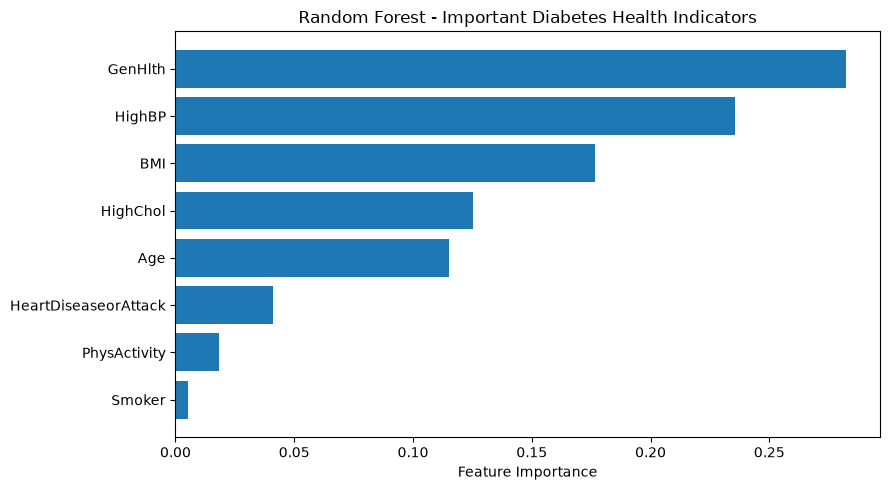

In [30]:
# ============================================================
# 8. Health Random Forest Feature Importance
# ============================================================

health_importance = pd.DataFrame({
    "Feature": health_features,
    "Importance": health_rf.feature_importances_
}).sort_values("Importance", ascending=False)

display(health_importance.round(4))

plt.figure(figsize=(9, 5))
plt.barh(health_importance["Feature"][::-1], health_importance["Importance"][::-1])
plt.xlabel("Feature Importance")
plt.title("Random Forest - Important Diabetes Health Indicators")
plt.tight_layout()
plt.show()

### Health Feature Importance Interpretation

General Health was the most important predictor (**0.2825**), followed by High Blood Pressure (**0.2357**), BMI (**0.1768**), High Cholesterol (**0.1253**), and Age (**0.1152**). Smoking had very low importance (**0.0051**) in this model, which was an unexpected finding compared with the other selected health indicators. These values show how useful the variables were for prediction within this Random Forest and should not be interpreted as causal effects.


## Decision Tree Depth and Overfitting

A Decision Tree can overfit when it grows too deep and learns patterns that do not generalize well. I compare several max_depth values using the same training and test data. F1 and ROC-AUC are used because the diabetes target is imbalanced.


In [31]:
# ============================================================
# 9. Health Decision Tree Depth Comparison
# ============================================================

depth_results = []

for depth in [3, 5, 10, 20]:
    model = DecisionTreeClassifier(
        criterion="entropy", max_depth=depth,
        class_weight="balanced", random_state=42
    )

    model.fit(Xh_train, yh_train)
    predictions = model.predict(Xh_test)
    probabilities = model.predict_proba(Xh_test)[:, 1]

    depth_results.append({
        "Max_Depth": depth,
        "Accuracy": accuracy_score(yh_test, predictions),
        "Recall": recall_score(yh_test, predictions),
        "F1": f1_score(yh_test, predictions),
        "ROC_AUC": roc_auc_score(yh_test, probabilities)
    })

depth_results = pd.DataFrame(depth_results)
display(depth_results.round(4))

,Max_Depth,Accuracy,Recall,F1,ROC_AUC
0,3,0.6098,0.8454,0.3765,0.7765
1,5,0.6916,0.7744,0.4117,0.8001
2,10,0.7195,0.7667,0.4324,0.8099
3,20,0.7190,0.6555,0.3940,0.7208


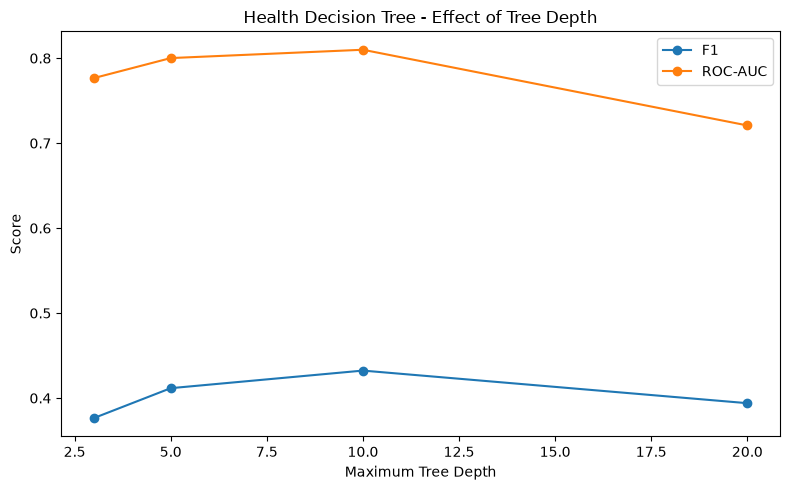

In [32]:
# Decision Tree Depth vs Performance

plt.figure(figsize=(8, 5))
plt.plot(depth_results["Max_Depth"], depth_results["F1"], marker="o", label="F1")
plt.plot(depth_results["Max_Depth"], depth_results["ROC_AUC"], marker="o", label="ROC-AUC")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("Score")
plt.title("Health Decision Tree - Effect of Tree Depth")
plt.legend()
plt.tight_layout()
plt.show()


### Tree Depth Interpretation

Increasing the maximum tree depth initially improved test performance. The Decision Tree with `max_depth=10` produced the best overall results among the tested depths, with accuracy of **0.7195**, F1 of **0.4324**, and ROC-AUC of **0.8099**. Increasing the depth to 20 did not improve accuracy and reduced recall to **0.6555**, F1 to **0.3940**, and ROC-AUC to **0.7208**. This pattern is consistent with poorer generalization as the tree becomes more complex and shows why controlling tree depth is important for limiting overfitting.


# Part 2 – Hospital Readmission Dataset

For the hospital dataset, the target is readmitted_30, where 1 means the patient was readmitted in less than 30 days and 0 means the patient was not readmitted within 30 days. The goal is to compare Decision Tree and Random Forest performance using selected hospital utilization variables.


In [33]:
# ============================================================
# 10. Load Hospital Dataset
# ============================================================

hospital_url = "https://raw.githubusercontent.com/jeganart/hospitaldatasetmilestone3/refs/heads/main/diabetic_data.csv"
hospital_df = pd.read_csv(hospital_url)

print("Dataset shape:", hospital_df.shape)
display(hospital_df.head())

# ============================================================
# 11. Create 30-Day Readmission Target
# ============================================================

hospital_df["readmitted_30"] = (hospital_df["readmitted"] == "<30").astype(int)

print("30-day readmission counts:")
print(hospital_df["readmitted_30"].value_counts())

print("\n30-day readmission percentages:")
print(hospital_df["readmitted_30"].value_counts(normalize=True).mul(100).round(2))


Dataset shape: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


30-day readmission counts:
readmitted_30
0    90409
1    11357
Name: count, dtype: int64

30-day readmission percentages:
readmitted_30
0    88.84
1    11.16
Name: proportion, dtype: float64


In [34]:
# ============================================================
# 12. Hospital Features and Train-Test Split
# ============================================================

hospital_features = [
    "time_in_hospital", "num_lab_procedures", "num_procedures",
    "num_medications", "number_outpatient", "number_emergency",
    "number_inpatient", "number_diagnoses"
]

X_hospital = hospital_df[hospital_features]
y_hospital = hospital_df["readmitted_30"]

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_hospital, y_hospital, test_size=0.20, random_state=42, stratify=y_hospital
)

print("Features:", hospital_features)
print("Missing values:", X_hospital.isnull().sum().sum())
print("Training observations:", len(Xr_train))
print("Testing observations:", len(Xr_test))

Features: ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
Missing values: 0
Training observations: 81412
Testing observations: 20354


## Hospital Decision Tree

I again use entropy and information gain. Tree depth and minimum leaf size are limited to reduce overfitting, and class_weight="balanced" is used because 30-day readmission is the minority class.


In [35]:
# ============================================================
# 13. Hospital Decision Tree
# ============================================================

hospital_tree = DecisionTreeClassifier(
    criterion="entropy", max_depth=5, min_samples_leaf=50,
    class_weight="balanced", random_state=42
)

hospital_tree.fit(Xr_train, yr_train)

hospital_tree_pred = hospital_tree.predict(Xr_test)
hospital_tree_prob = hospital_tree.predict_proba(Xr_test)[:, 1]

hospital_tree_accuracy = accuracy_score(yr_test, hospital_tree_pred)
hospital_tree_precision = precision_score(yr_test, hospital_tree_pred)
hospital_tree_recall = recall_score(yr_test, hospital_tree_pred)
hospital_tree_f1 = f1_score(yr_test, hospital_tree_pred)
hospital_tree_auc = roc_auc_score(yr_test, hospital_tree_prob)

print("HOSPITAL DECISION TREE")
print("Accuracy:", round(hospital_tree_accuracy, 4))
print("Precision:", round(hospital_tree_precision, 4))
print("Recall:", round(hospital_tree_recall, 4))
print("F1 Score:", round(hospital_tree_f1, 4))
print("ROC-AUC:", round(hospital_tree_auc, 4))

HOSPITAL DECISION TREE
Accuracy: 0.6725
Precision: 0.1697
Recall: 0.4971
F1 Score: 0.2531
ROC-AUC: 0.6322


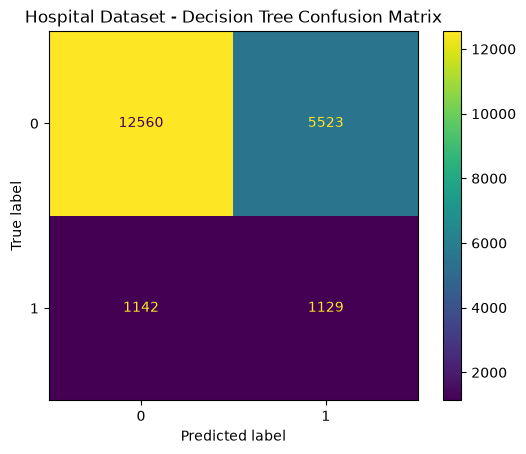

In [36]:
# Hospital Decision Tree Confusion Matrix

ConfusionMatrixDisplay.from_predictions(yr_test, hospital_tree_pred)
plt.title("Hospital Dataset - Decision Tree Confusion Matrix")
plt.show()


## Hospital Random Forest

The Random Forest uses many trees and combines their predictions. I use the same selected hospital features and the same train-test split so the two hospital models can be compared directly.


In [37]:
# ============================================================
# 14. Hospital Random Forest
# ============================================================

hospital_rf = RandomForestClassifier(
    n_estimators=100, max_depth=10, min_samples_leaf=20,
    class_weight="balanced", random_state=42, n_jobs=-1
)

hospital_rf.fit(Xr_train, yr_train)

hospital_rf_pred = hospital_rf.predict(Xr_test)
hospital_rf_prob = hospital_rf.predict_proba(Xr_test)[:, 1]

hospital_rf_accuracy = accuracy_score(yr_test, hospital_rf_pred)
hospital_rf_precision = precision_score(yr_test, hospital_rf_pred)
hospital_rf_recall = recall_score(yr_test, hospital_rf_pred)
hospital_rf_f1 = f1_score(yr_test, hospital_rf_pred)
hospital_rf_auc = roc_auc_score(yr_test, hospital_rf_prob)

print("HOSPITAL RANDOM FOREST")
print("Accuracy:", round(hospital_rf_accuracy, 4))
print("Precision:", round(hospital_rf_precision, 4))
print("Recall:", round(hospital_rf_recall, 4))
print("F1 Score:", round(hospital_rf_f1, 4))
print("ROC-AUC:", round(hospital_rf_auc, 4))


HOSPITAL RANDOM FOREST
Accuracy: 0.6538
Precision: 0.1672
Recall: 0.5284
F1 Score: 0.254
ROC-AUC: 0.6417


In [38]:
# ============================================================
# 15. Compare Hospital Models
# ============================================================

hospital_results = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Accuracy": [hospital_tree_accuracy, hospital_rf_accuracy],
    "Precision": [hospital_tree_precision, hospital_rf_precision],
    "Recall": [hospital_tree_recall, hospital_rf_recall],
    "F1": [hospital_tree_f1, hospital_rf_f1],
    "ROC_AUC": [hospital_tree_auc, hospital_rf_auc]
})

display(hospital_results.round(4))


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Decision Tree,0.6725,0.1697,0.4971,0.2531,0.6322
1,Random Forest,0.6538,0.1672,0.5284,0.2540,0.6417


### Hospital Model Interpretation

Random Forest did not clearly outperform the Decision Tree on the hospital dataset. It increased recall from **0.4971 to 0.5284** and ROC-AUC from **0.6322 to 0.6417**, meaning it identified slightly more 30-day readmissions and provided slightly better discrimination. However, accuracy decreased from **0.6725 to 0.6538**, precision decreased slightly, and F1 remained nearly unchanged at approximately **0.25**. Therefore, Random Forest provided a modest improvement in identifying positive cases, but not a substantial improvement in overall predictive performance.


,Feature,Importance
6,number_inpatient,0.4401
1,num_lab_procedures,0.1124
3,num_medications,0.1083
0,time_in_hospital,0.0989
5,number_emergency,0.0795
7,number_diagnoses,0.0760
2,num_procedures,0.0497
4,number_outpatient,0.0351


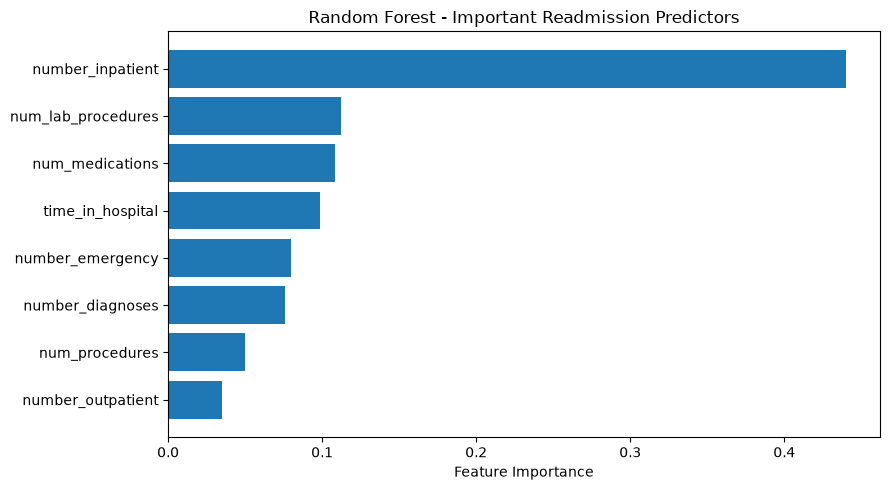

In [39]:
# ============================================================
# 16. Hospital Random Forest Feature Importance
# ============================================================

hospital_importance = pd.DataFrame({
    "Feature": hospital_features,
    "Importance": hospital_rf.feature_importances_
}).sort_values("Importance", ascending=False)

display(hospital_importance.round(4))

plt.figure(figsize=(9, 5))
plt.barh(hospital_importance["Feature"][::-1], hospital_importance["Importance"][::-1])
plt.xlabel("Feature Importance")
plt.title("Random Forest - Important Readmission Predictors")
plt.tight_layout()
plt.show()


### Hospital Feature Importance Interpretation

number_inpatient was by far the most important predictor, with an importance of **0.4401**. The next most important variables were num_lab_procedures (**0.1124**), num_medications (**0.1083**), and time_in_hospital (**0.0989**). This suggests that prior inpatient utilization contained particularly useful predictive information for 30-day readmission in this model. Feature importance describes predictive usefulness and does not establish causation.

In [40]:
# ============================================================
# 17. Final Model Comparison
# ============================================================

all_results = pd.DataFrame({
    "Dataset": ["Health", "Health", "Hospital", "Hospital"],
    "Model": ["Decision Tree", "Random Forest", "Decision Tree", "Random Forest"],
    "Accuracy": [health_tree_accuracy, health_rf_accuracy, hospital_tree_accuracy, hospital_rf_accuracy],
    "Precision": [health_tree_precision, health_rf_precision, hospital_tree_precision, hospital_rf_precision],
    "Recall": [health_tree_recall, health_rf_recall, hospital_tree_recall, hospital_rf_recall],
    "F1": [health_tree_f1, health_rf_f1, hospital_tree_f1, hospital_rf_f1],
    "ROC_AUC": [health_tree_auc, health_rf_auc, hospital_tree_auc, hospital_rf_auc]
})

display(all_results.round(4))

,Dataset,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Health,Decision Tree,0.6916,0.2803,0.7744,0.4117,0.8001
1,Health,Random Forest,0.7196,0.3030,0.7786,0.4362,0.8191
2,Hospital,Decision Tree,0.6725,0.1697,0.4971,0.2531,0.6322
3,Hospital,Random Forest,0.6538,0.1672,0.5284,0.2540,0.6417


# Week 6 Summary and Interpretation

I applied Decision Trees and Random Forests to both healthcare datasets. For the BRFSS diabetes dataset, Random Forest performed better than the single Decision Tree across all evaluation metrics. Accuracy increased from **0.6916 to 0.7196**, F1 from **0.4117 to 0.4362**, and ROC-AUC from **0.8001 to 0.8191**, while recall remained high at **0.7786**. General Health, High Blood Pressure, BMI, High Cholesterol, and Age were the most important predictors. One unexpected result was the very low importance of Smoking (**0.0051**) compared with the other selected health indicators. These feature importances represent predictive associations rather than causal effects.

I also examined the effect of Decision Tree complexity by comparing maximum depths of 3, 5, 10, and 20. Test performance improved through **depth 10**, which achieved the highest F1 (**0.4324**) and ROC-AUC (**0.8099**). At depth 20, F1 decreased to **0.3940** and ROC-AUC to **0.7208**, showing that additional tree complexity did not improve test performance and was consistent with poorer generalization. This demonstrated why limiting tree depth is useful when controlling overfitting. Random Forest further improved ROC-AUC to **0.8191**, showing the benefit of combining multiple trees rather than relying on a single tree.

The hospital readmission problem was more difficult. Random Forest increased recall from **0.4971 to 0.5284** and ROC-AUC from **0.6322 to 0.6417**, but accuracy decreased from **0.6725 to 0.6538**, and F1 remained near **0.25**. Therefore, Random Forest provided only a modest improvement in identifying positive cases and did not clearly outperform the Decision Tree across all metrics. number_inpatient was the strongest hospital predictor with an importance of **0.4401**. Because both datasets were imbalanced, accuracy alone was not sufficient; precision, recall, F1, ROC-AUC, and confusion matrices provided a more complete evaluation. Overall, Random Forest clearly improved diabetes classification, while the hospital results demonstrated that a more complex ensemble model does not automatically produce substantially better predictions.
